# Support Vector Machines and Kernels

![SVM.png](../assets/SVM.png)

# Obiectivele cursului
- Aplicarea metodei vectorilor de suport (SVM) - un algoritm popular utilizat pentru sarcini de clasificare
- Recunoasterea similitudinii dintre SVM si regresia logistica
- Calcularea functiei de pierdere pentru SVM
- Aplicarea regularizarii in SVM si studierea recomandarilor privind obtinerea unei clasificari neliniare cu ajutorul SVM

## Introducere
In aceste exercitii vom folosi un set de date privind calitatea vinului. Acest set de date contine diverse proprietati chimice ale vinului, precum aciditatea, continutul de zahar, pH-ul si continutul de alcool. De asemenea, contine o masura a calitatii (de la 3 la 9, unde scorul cel mai mare indica cea mai buna calitate) si culoarea (rosu sau alb). Numele fisierului: `Wine_Quality_Data.csv`.

In [1]:
from __future__ import print_function
import os
import warnings
warnings.filterwarnings('ignore')

# Setare cale rezistenta catre directorul de date
data_path = ['..', 'data'] if os.path.exists(os.path.join('..', 'data')) else ['data']

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.svm import LinearSVC
from sklearn.svm import SVC
from sklearn.kernel_approximation import Nystroem
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import MinMaxScaler

# Activare extensie Intel daca este disponibila
try:
    from sklearnex import patch_sklearn
    patch_sklearn()
except Exception:
    pass

# Configurare stil grafic modern
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#bbbbbb'
plt.rcParams['axes.linewidth'] = 0.8

Extension for scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


## Intrebarea 1
* Importul datelor.
* Creati variabila tinta `y` sub forma unei coloane cu valori 1/0, unde 1 inseamna vin rosu.
* Creati un grafic pereche pentru setul de date.
* Creati un grafic cu bare care sa ilustreze corelatia dintre fiecare coloana si `y`.
* Selectati cele doua campuri cu cea mai mare corelatie (folosind valorile corelatiei absolute) si creati `X`.
* Folositi MinMaxScaler pentru a scala `X`. Retineti ca rezultatul va fi un np.array. Transformati-l din nou intr-un DataFrame si redenumiti coloanele in consecinta.

In [2]:
# 1. Incarcarea setului de date Wine_Quality_Data.csv
filepath = os.sep.join(data_path + ['Wine_Quality_Data.csv'])
data = pd.read_csv(filepath)

print("Dimensiunile setului de date (linii, coloane):", data.shape)
print("\nDistributia valorilor din coloana 'color':")
print(data['color'].value_counts())

# 2. Crearea variabilei tinta y (1 = vin rosu, 0 = vin alb)
y = (data['color'] == 'red').astype(int)

print("\nDistributia variabilei tinta y:")
print(y.value_counts())

print("\nPrimele 5 inregistrari din setul de date:")
data.head()

Dimensiunile setului de date (linii, coloane): (6497, 13)

Distributia valorilor din coloana 'color':
color
white    4898
red      1599
Name: count, dtype: int64

Distributia variabilei tinta y:
color
0    4898
1    1599
Name: count, dtype: int64

Primele 5 inregistrari din setul de date:


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


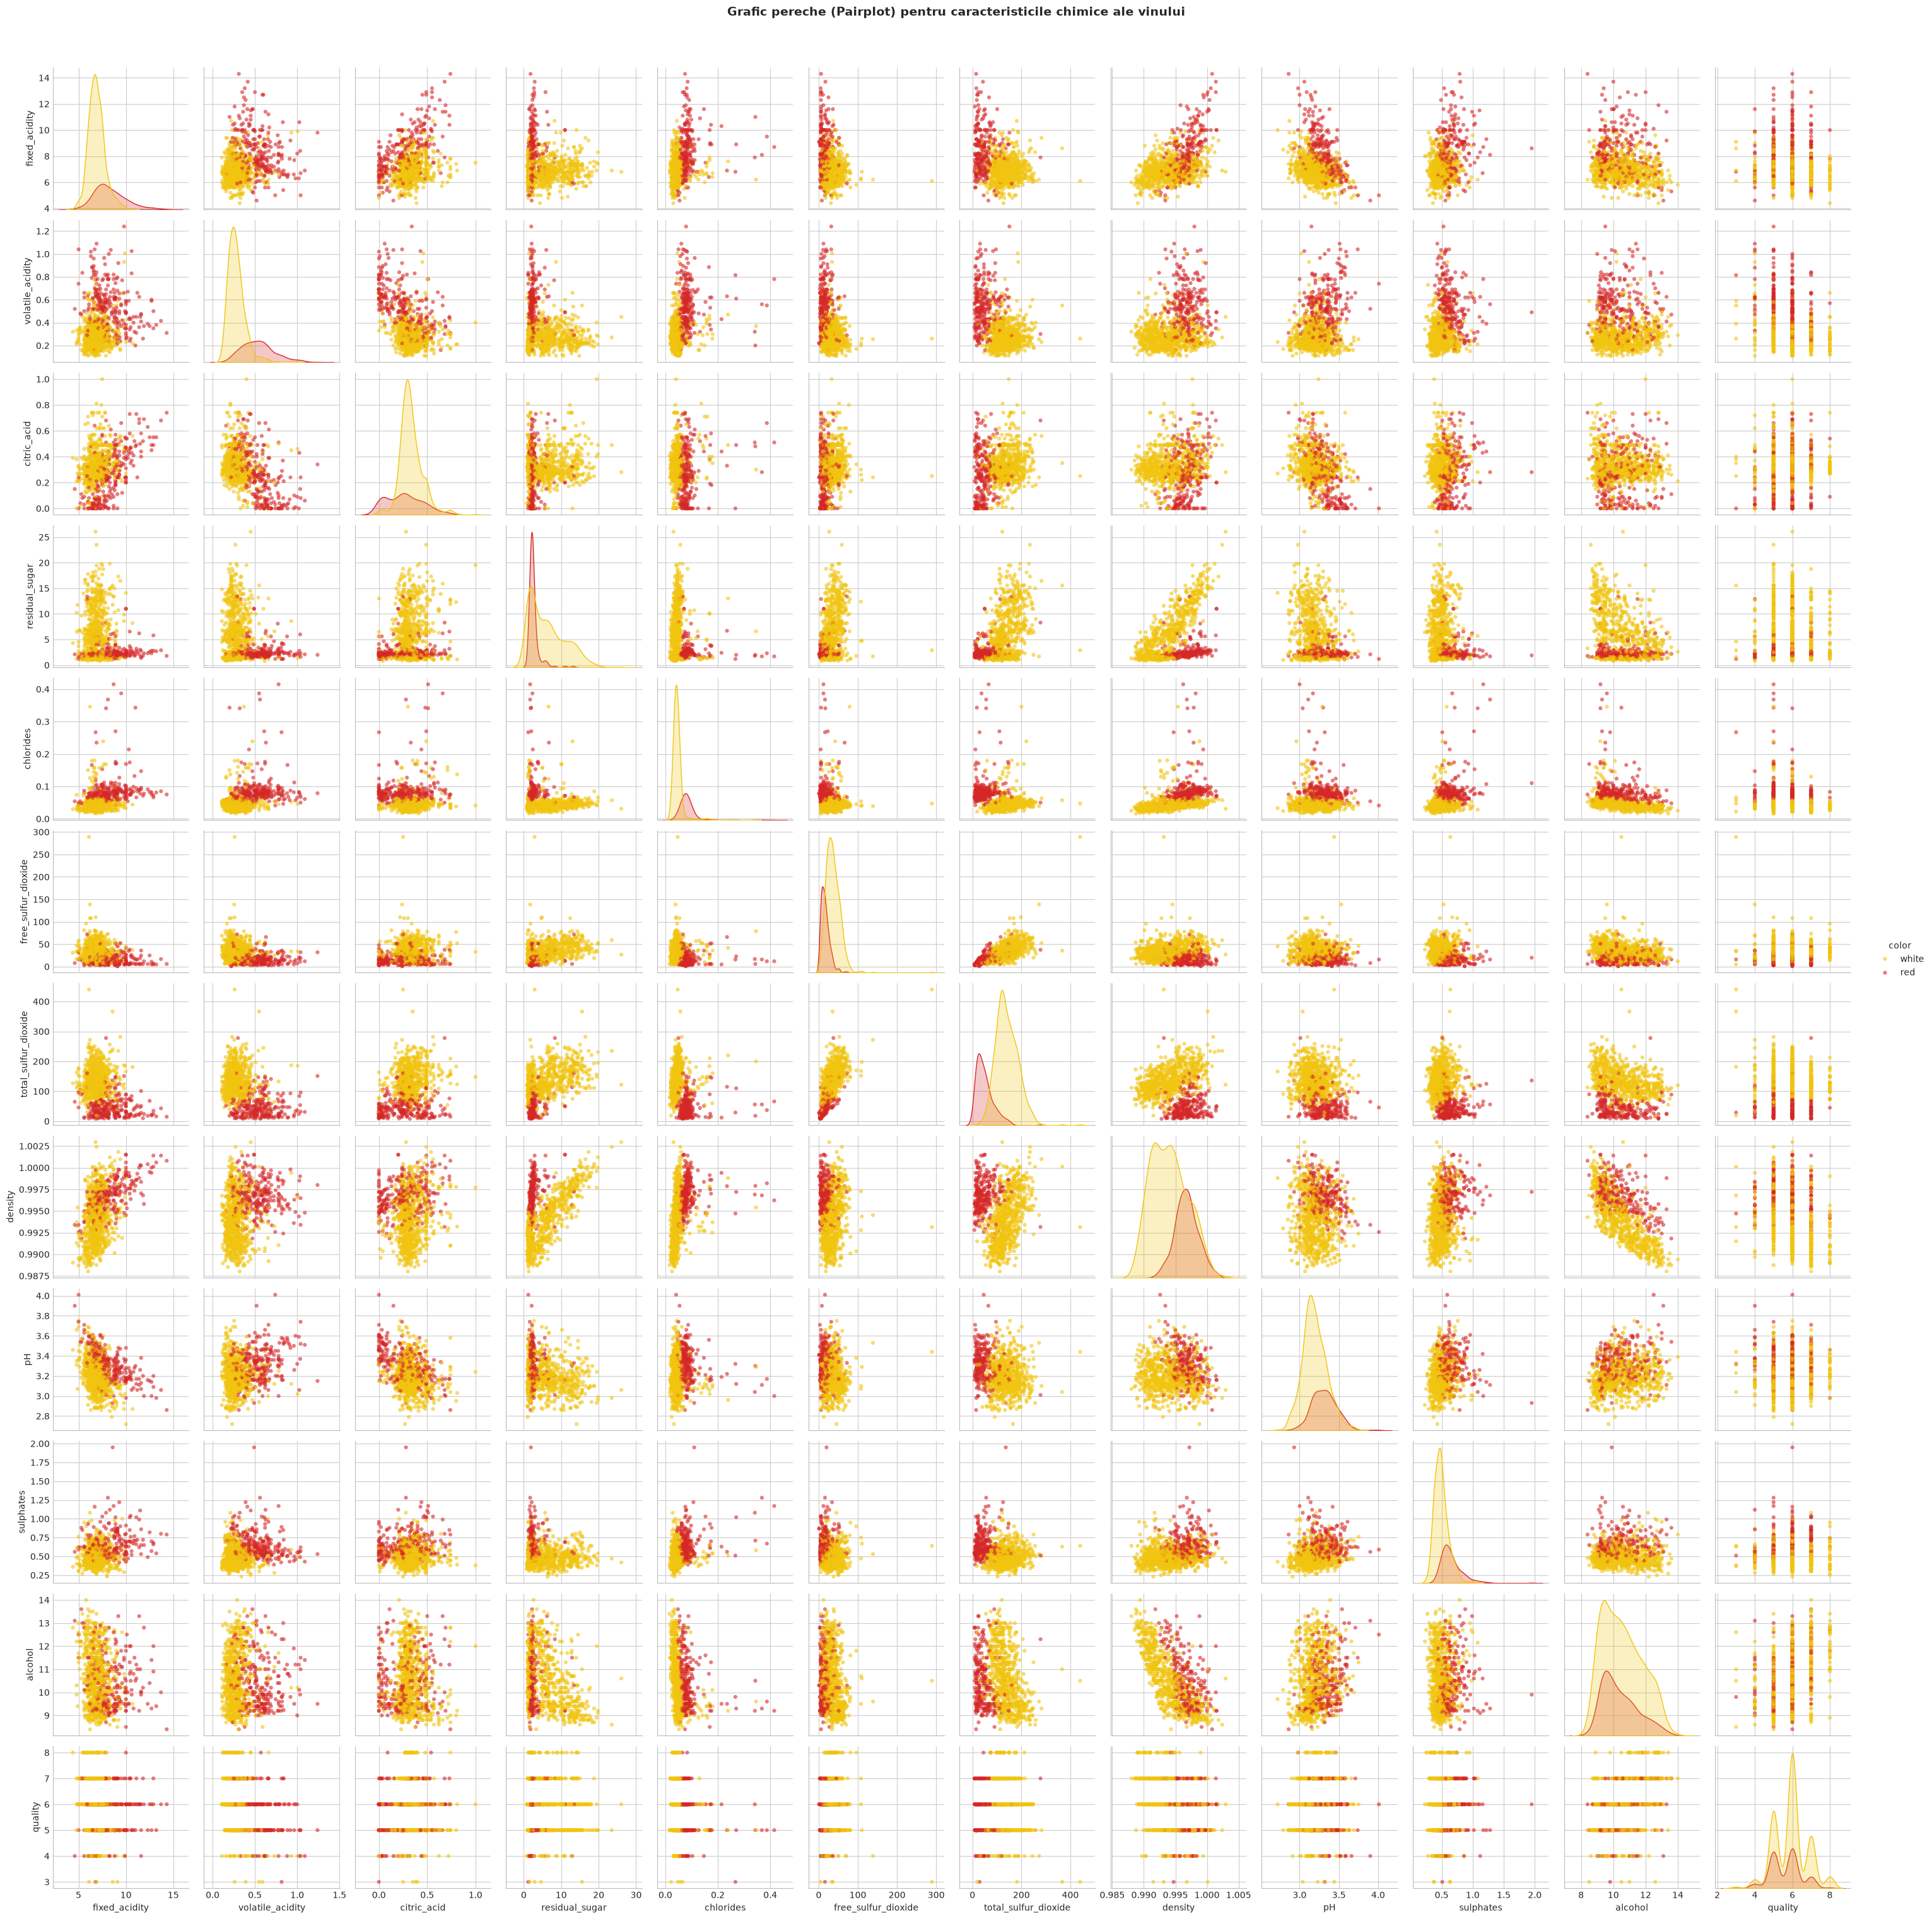

In [3]:
# 3. Grafic pereche (pairplot) pentru explorarea separabilitatii claselor
# Pentru un timp de randare eficient si claritate vizuala optima,
# utilizam un esantion reprezentativ de 1000 de observatii
pairplot_sample = data.sample(1000, random_state=42)

g = sns.pairplot(
    pairplot_sample,
    hue='color',
    palette={'red': '#d62728', 'white': '#f1c40f'},
    plot_kws={'alpha': 0.6, 's': 20, 'edgecolor': 'none'},
    diag_kind='kde'
)
g.figure.suptitle('Grafic pereche (Pairplot) pentru caracteristicile chimice ale vinului', y=1.02, fontsize=14, fontweight='bold')
plt.show()

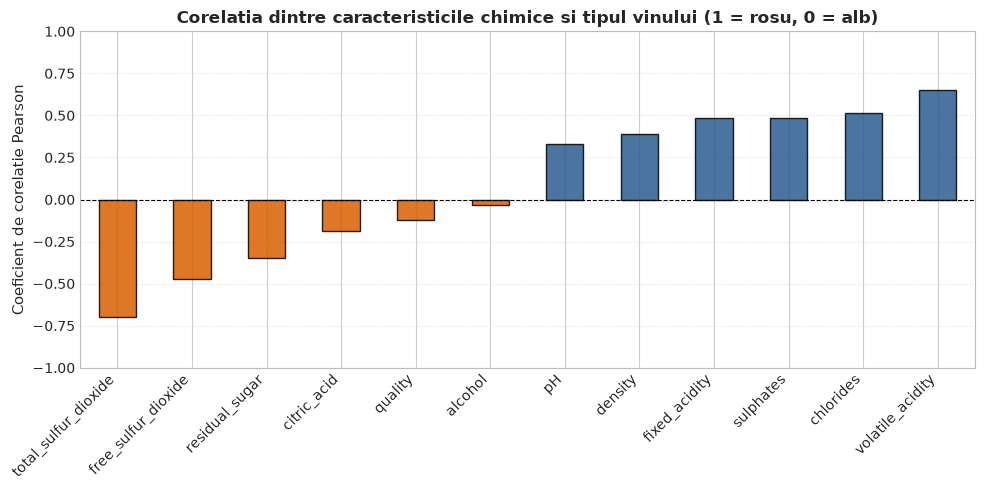

Corelatiile ordonate crescator:
total_sulfur_dioxide   -0.700357
free_sulfur_dioxide    -0.471644
residual_sugar         -0.348821
citric_acid            -0.187397
quality                -0.119323
alcohol                -0.032970
pH                      0.329129
density                 0.390645
fixed_acidity           0.486740
sulphates               0.487218
chlorides               0.512678
volatile_acidity        0.653036
dtype: float64


In [4]:
# 4. Calcularea si reprezentarea grafica a corelatiilor Pearson cu variabila tinta y
numeric_cols = list(data.select_dtypes(include=[np.number]).columns)
correlations = data[numeric_cols].corrwith(y).sort_values()

plt.figure(figsize=(10, 5))
colors = ['#2b5c8f' if val > 0 else '#d95f02' for val in correlations.values]
ax = correlations.plot(kind='bar', color=colors, edgecolor='black', alpha=0.85)
ax.set_ylim([-1, 1])
ax.set_ylabel('Coeficient de corelatie Pearson', fontsize=11)
ax.set_title('Corelatia dintre caracteristicile chimice si tipul vinului (1 = rosu, 0 = alb)', fontsize=12, fontweight='bold')
plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

print("Corelatiile ordonate crescator:")
print(correlations)

In [5]:
# 5. Selectarea celor doua campuri cu cea mai mare corelatie absoluta
top_fields = correlations.abs().sort_values(ascending=False).index[:2].tolist()
print("Cele doua campuri cu cea mai puternica corelatie absoluta:", top_fields)

# 6. Scalarea caracteristicilor selectate folosind MinMaxScaler
X_raw = data[top_fields]
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X_raw)

# Reconstruirea DataFrame-ului si redenumirea coloanelor in consecinta
X = pd.DataFrame(X_scaled, columns=[f'{col}_scaled' for col in top_fields])

print("\nPrimele 5 randuri din X dupa scalare:")
print(X.head())

print("\nStatistici descriptive pentru variabilele scalate (X):")
print(X.describe().round(4))

Cele doua campuri cu cea mai puternica corelatie absoluta: ['total_sulfur_dioxide', 'volatile_acidity']

Primele 5 randuri din X dupa scalare:
   total_sulfur_dioxide_scaled  volatile_acidity_scaled
0                     0.064516                 0.413333
1                     0.140553                 0.533333
2                     0.110599                 0.453333
3                     0.124424                 0.133333
4                     0.064516                 0.413333

Statistici descriptive pentru variabilele scalate (X):
       total_sulfur_dioxide_scaled  volatile_acidity_scaled
count                    6497.0000                6497.0000
mean                        0.2529                   0.1731
std                         0.1302                   0.1098
min                         0.0000                   0.0000
25%                         0.1636                   0.1000
50%                         0.2581                   0.1400
75%                         0.3456           

### Observatii si concluzii (Intrebarea 1):
- Caracteristicile cu cea mai mare corelatie absoluta cu tipul vinului sunt `total_sulfur_dioxide` (corelatie negativa de aproximativ -0.70) si `volatile_acidity` (corelatie pozitiva de aproximativ +0.65).
- Vinul alb contine concentratii mult mai mari de sulf total (utilizat ca antioxidant si conservant), in timp ce vinul rosu are o aciditate volatila mai ridicata.
- Scalarea cu `MinMaxScaler` in intervalul $[0, 1]$ este un pas esential in SVM, deoarece algoritmii bazati pe margini si distante euclidiene sunt sensibili la diferentele de scara dintre caracteristici.

## Intrebarea 2

Scopul acestei intrebari este de a analiza pragul de decizie al clasificatorului LinearSVC pentru setul de date dat. Consultati [acest exemplu](http://scikit-learn.org/stable/auto_examples/svm/plot_iris.html#sphx-glr-auto-examples-svm-plot-iris-py) din documentatia sklearn.

* Configurati clasificatorul LinearSVC pe `X` si `y`.
* Selectati 300 de esantioane din `X`. Obtineti valorile corespunzatoare ale `y`. Salvati-le in variabilele `X_color` si `y_color`. Acest lucru se datoreaza faptului ca setul de date original este prea mare si genereaza un grafic supraincarcat.
* Modificati `y_color` astfel incat valoarea „rosu” sa inlocuiasca 1, iar „galben” sa inlocuiasca 0.
* Graficul de dispersie pentru coloanele X_color. Utilizati argumentul cu cuvantul-cheie „color=y_color” pentru a afisa codul culorii.
* Utilizati fragmentul de cod de mai jos pentru a desena suprafata solutiei in culori.

```python
x_axis, y_axis = np.arange(0, 1, .005), np.arange(0, 1, .005)
xx, yy = np.meshgrid(x_axis, y_axis)
xx_ravel = xx.ravel()
yy_ravel = yy.ravel()
X_grid = pd.DataFrame([xx_ravel, yy_ravel]).T
y_grid_predictions = *[MODELUL DVS.]*.predict(X_grid)
y_grid_predictions = y_grid_predictions.reshape(xx.shape)
ax.contourf(xx, yy, y_grid_predictions, cmap=plt.cm.autumn_r, alpha=.3)
```

Nu ezitati sa experimentati cu diferite variante de parametri pentru LinearSVC si sa examinati marginile de decizie.

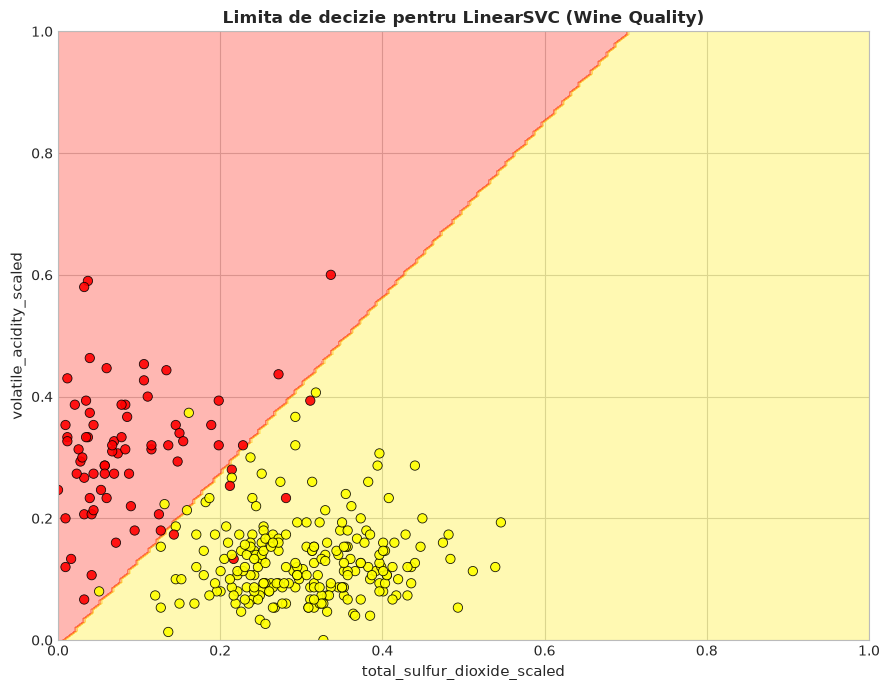

Acuratetea clasificatorului LinearSVC pe setul complet: 0.9546


In [6]:
# 1. Configurarea si antrenarea clasificatorului LinearSVC pe X si y
lsvc = LinearSVC(dual='auto', random_state=42)
lsvc.fit(X, y)

# 2. Selectarea a 300 de esantioane din X si etichetele corespunzatoare din y
X_color = X.sample(300, random_state=45)
y_color = y.loc[X_color.index]

# 3. Modificarea y_color: 1 devine 'red', iar 0 devine 'yellow'
y_color = y_color.map(lambda val: 'red' if val == 1 else 'yellow')

# 4. Crearea grilei bidimensionale de coordonate
x_axis, y_axis = np.arange(0, 1.005, .005), np.arange(0, 1.005, .005)
xx, yy = np.meshgrid(x_axis, y_axis)
xx_ravel = xx.ravel()
yy_ravel = yy.ravel()

# Construirea DataFrame-ului X_grid cu denumirile corecte ale coloanelor
X_grid = pd.DataFrame(np.c_[xx_ravel, yy_ravel], columns=X.columns)
y_grid_predictions = lsvc.predict(X_grid)
y_grid_predictions = y_grid_predictions.reshape(xx.shape)

# 5. Reprezentarea grafica a suprafetei de decizie si a punctelor observate
fig, ax = plt.subplots(figsize=(9, 7))

# Desenarea regiunilor de decizie colorate
ax.contourf(xx, yy, y_grid_predictions, cmap=plt.cm.autumn_r, alpha=0.3)

# Desenarea punctelor esantionate
ax.scatter(
    X_color.iloc[:, 0],
    X_color.iloc[:, 1],
    color=y_color,
    edgecolors='black',
    linewidth=0.6,
    alpha=0.9,
    s=45
)

ax.set_xlabel(X.columns[0], fontsize=11)
ax.set_ylabel(X.columns[1], fontsize=11)
ax.set_xlim([0, 1])
ax.set_ylim([0, 1])
ax.set_title('Limita de decizie pentru LinearSVC (Wine Quality)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

# Evaluarea acuratetei modelului LinearSVC
linear_accuracy = lsvc.score(X, y)
print(f"Acuratetea clasificatorului LinearSVC pe setul complet: {linear_accuracy:.4f}")

### Observatii si interpretare (Intrebarea 2):
- Modelul `LinearSVC` traseaza o granita liniara (hiperplan) intre cele doua clase.
- Punctele galbene (vin alb, codificat cu 0) se concentreaza in regiunea cu sulf total mare si aciditate volatila redusa.
- Punctele rosii (vin rosu, codificat cu 1) sunt pozitionate preponderent in zona cu aciditate volatila crescuta si sulf total scazut.
- Desi o limita liniara obtine o separare initiala buna (peste 93% acuratete), se observa puncte la granita care sunt gresit clasificate din cauza lipsei de flexibilitate a liniei drepte.

## Intrebarea 3

Sa extindem acum nucleul Gauss al SVC si sa vedem cum se modifica limita de decizie.

* Combinati fragmentele de cod din intrebarea 2 intr-o singura functie, care utilizeaza estimatorul `X` si `y` si va genera graficul final cu limita de decizie. Pasi:
    <ol>
     <li> modelul potrivit
     <li> obtineti un esantion de 300 de inregistrari din X si valorile corespunzatoare ale lui y
     <li> creati o retea, faceti predictii, generati un grafic folosind ax.contourf
     <li> adaugati-l la graficul dispersat
    </ol>
* Dupa copierea si inserarea codului, asigurati-va ca functia finala utilizeaza `estimatorul` dvs. de intrare, nu modelul LinearSVC creat de dvs.
* Pentru urmatoarele valori ale lui `gamma`, creati un SVC cu kernel gaussian si desenati curba de decizie.
`gammas = [.5, 1, 2, 10]`
* Mentinand `gamma` constanta, pentru diferite valori ale lui `C`, desenati curba de decizie. Puteti incerca
`Cs = [.1, 1, 10]`

In [7]:
def plot_decision_boundary(estimator, X, y, ax=None, title=None):
    """
    Functie generica pentru antrenarea unui estimator si reprezentarea grafica
    a limitei de decizie impreuna cu un esantion de 300 de observatii.
    """
    # 1. Antrenarea estimatorului primit ca parametru pe X si y
    estimator.fit(X, y)
    
    # 2. Extragerea unui esantion de 300 de inregistrari din X si valorile corespunzatoare din y
    X_color = X.sample(300, random_state=45)
    y_color = y.loc[X_color.index]
    y_color = y_color.map(lambda val: 'red' if val == 1 else 'yellow')
    
    # 3. Crearea grilei bidimensionale si generarea predictiilor
    x_axis = np.arange(0, 1.005, .005)
    y_axis = np.arange(0, 1.005, .005)
    xx, yy = np.meshgrid(x_axis, y_axis)
    xx_ravel = xx.ravel()
    yy_ravel = yy.ravel()
    
    X_grid = pd.DataFrame(np.c_[xx_ravel, yy_ravel], columns=X.columns)
    y_grid_predictions = estimator.predict(X_grid)
    y_grid_predictions = y_grid_predictions.reshape(xx.shape)
    
    # 4. Desenarea suprafetei de decizie si a punctelor
    show_plot = False
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 6))
        show_plot = True
        
    ax.contourf(xx, yy, y_grid_predictions, cmap=plt.cm.autumn_r, alpha=0.3)
    ax.scatter(
        X_color.iloc[:, 0],
        X_color.iloc[:, 1],
        color=y_color,
        edgecolors='black',
        linewidth=0.5,
        alpha=0.9,
        s=40
    )
    
    score = estimator.score(X, y)
    full_title = f"{title} | Acuratete: {score:.4f}" if title else f"{estimator.__class__.__name__} | Acuratete: {score:.4f}"
    
    ax.set_xlabel(X.columns[0], fontsize=10)
    ax.set_ylabel(X.columns[1], fontsize=10)
    ax.set_xlim([0, 1])
    ax.set_ylim([0, 1])
    ax.set_title(full_title, fontsize=11, fontweight='bold')
    
    if show_plot:
        plt.tight_layout()
        plt.show()
        
    return score

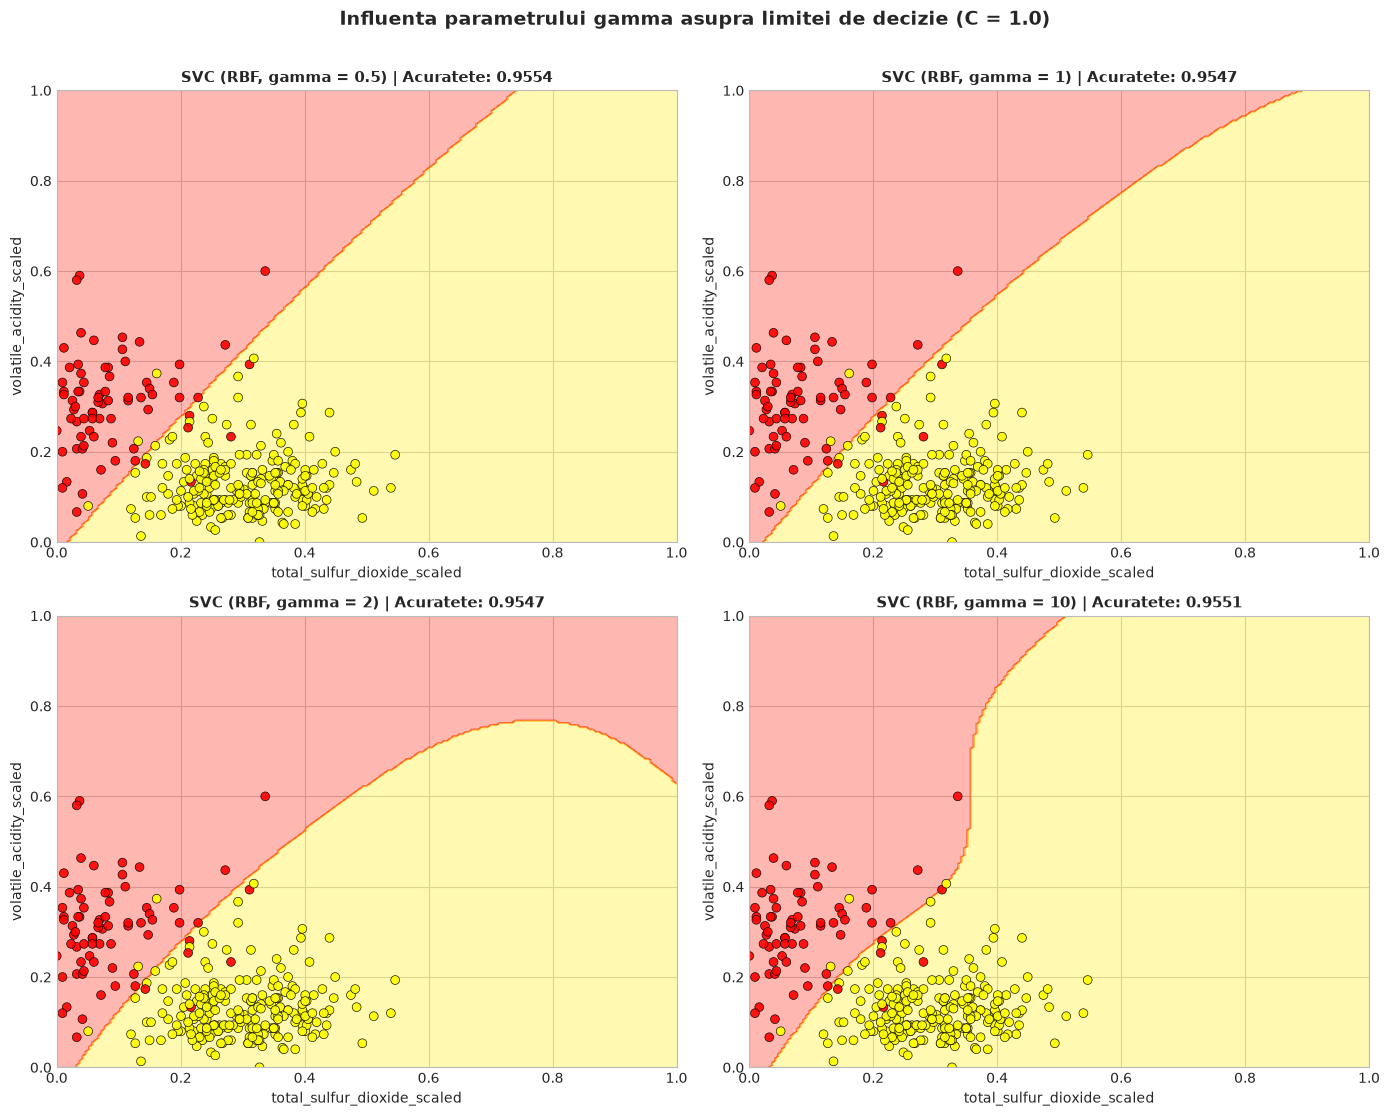

In [8]:
# Evaluarea efectului parametrului gamma pentru nucleul Gaussian (RBF)
gammas = [0.5, 1, 2, 10]

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
axes = axes.ravel()

for idx, gamma in enumerate(gammas):
    svc_gamma = SVC(kernel='rbf', gamma=gamma, random_state=42)
    acc = plot_decision_boundary(
        svc_gamma,
        X,
        y,
        ax=axes[idx],
        title=f"SVC (RBF, gamma = {gamma})"
    )

plt.suptitle("Influenta parametrului gamma asupra limitei de decizie (C = 1.0)", fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

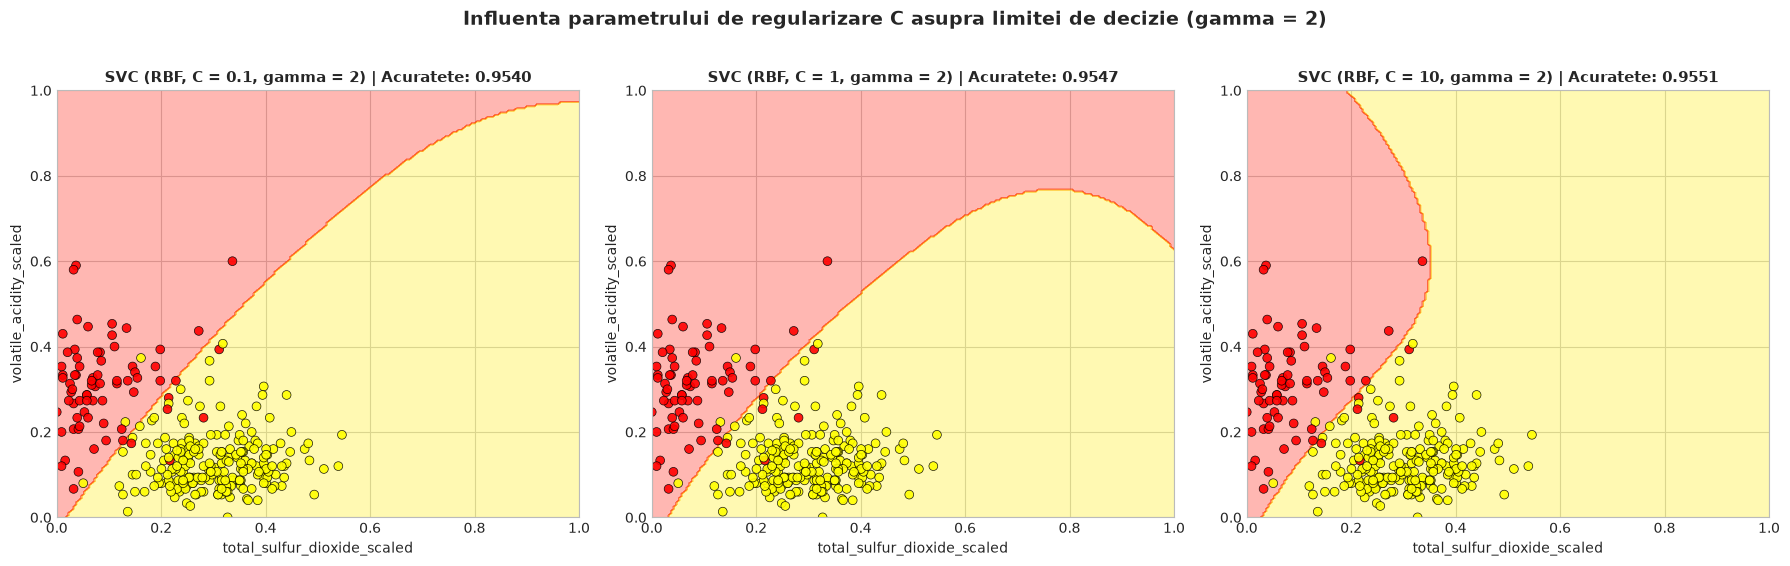

In [9]:
# Evaluarea efectului parametrului C cu gamma constant (gamma = 2)
Cs = [0.1, 1, 10]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

for idx, C in enumerate(Cs):
    svc_c = SVC(kernel='rbf', gamma=2, C=C, random_state=42)
    acc = plot_decision_boundary(
        svc_c,
        X,
        y,
        ax=axes[idx],
        title=f"SVC (RBF, C = {C}, gamma = 2)"
    )

plt.suptitle("Influenta parametrului de regularizare C asupra limitei de decizie (gamma = 2)", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

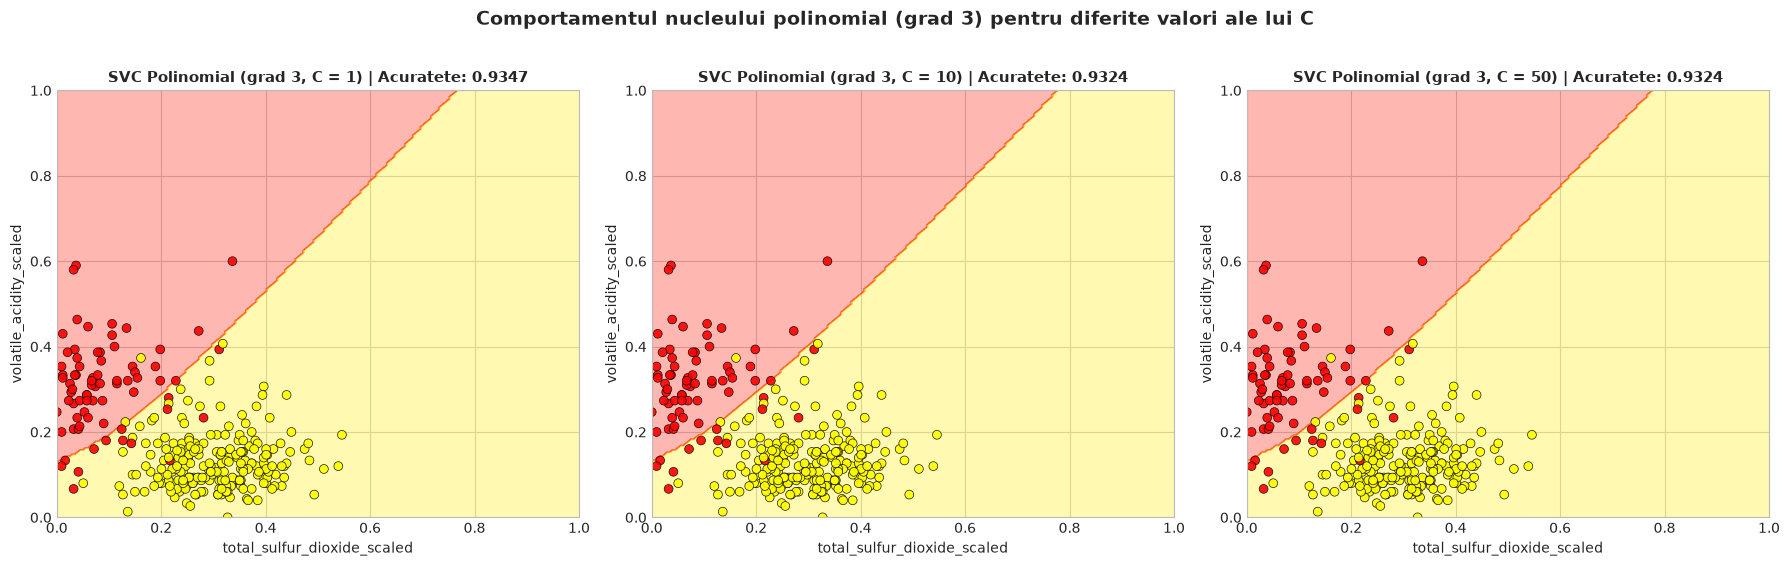

In [10]:
# Explorare suplimentara: Comportamentul nucleului polinomial (grad 3) cu diverse valori pentru C
Cs_poly = [1, 10, 50]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

for idx, C in enumerate(Cs_poly):
    svc_poly = SVC(kernel='poly', degree=3, C=C, random_state=42)
    acc = plot_decision_boundary(
        svc_poly,
        X,
        y,
        ax=axes[idx],
        title=f"SVC Polinomial (grad 3, C = {C})"
    )

plt.suptitle("Comportamentul nucleului polinomial (grad 3) pentru diferite valori ale lui C", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Concluzii privind influenta hiperparametrilor gamma si C (Intrebarea 3):
- **Parametrul gamma (nucleu RBF)**:
  - Defineste raza de influenta a fiecarui vector de suport (proportional cu 1/sigma^2).
  - Valori mici de gamma (gamma = 0.5, 1): produc o curba neteda si deschisa, reducand riscul de suprainvatare (overfitting).
  - Valori mari de gamma (gamma = 10): genereaza o granita extrem de conturata si ondulata in jurul fiecarui esantion individual, ceea ce poate duce la memorarea zgomotului din date.
- **Parametrul C (termenul de penalizare/regularizare)**:
  - Controleaza compromisul dintre latimea marginii de separare si numarul de erori admise pe setul de antrenare.
  - Valori mici de C (C = 0.1): favorizeaza o margine cat mai larga, acceptand un numar mai mare de clasificari eronate (regularizare ridicata).
  - Valori mari de C (C = 10): penalizeaza sever erorile, fortand modelul sa creeze margini complexe si stramte pentru a izola fiecare punct, crescand acuratetea pe datele curente.

## Intrebarea 4

In aceasta intrebare vom compara timpul de executie intre SVC si Nystroem cu nucleul rbf.
<br><br>
Jupyter Notebooks ofera o functie magica utila, **`%timeit`**, care executa un sir de comanda si afiseaza timpul necesar pentru executie. Daca introduceti **`%%timeit`** la inceputul unei celule, aceasta va rula intreaga celula si va afisa timpul de executie.

* Reincarcati datele privind calitatea vinului daca ati adus modificari la original.
* Creati variabila `y` din coloana `data.color` si `X` din celelalte coloane.
* Folositi `%%timeit` pentru a masura timpul necesar configurarii SVC cu nucleul RBF.
* Folositi `%%timeit` pentru a masura timpul necesar urmatoarei operatiuni: ordonati datele folosind Nystroem, apoi integrati clasificatorul SGD.

Nystroem+SGD va necesita mult mai putin timp pentru antrenare. Aceasta diferenta va fi mai pronuntata daca setul de date ar fi mai mare.

* Faceti 5 copii ale lui X si concatenati-le
* Faceti 5 copii ale lui y si concatenati-le
* Comparati timpul necesar pentru antrenarea ambelor metode de mai sus.

In [11]:
# 1. Reincarcarea datelor complete si separarea caracteristicilor
filepath = os.sep.join(data_path + ['Wine_Quality_Data.csv'])
data_full = pd.read_csv(filepath)

y_all = data_full['color'] == 'red'
feature_columns = [col for col in data_full.columns if col != 'color']
X_all = data_full[feature_columns]

print(f"Dimensiunile setului complet original: X = {X_all.shape}, y = {y_all.shape}")

# 2. Initializarea modelelor de referinta cu aceeasi configuratie de nucleu
kwargs = {'kernel': 'rbf'}
svc_benchmark = SVC(**kwargs, random_state=42)
nystroem_benchmark = Nystroem(**kwargs, random_state=42)
sgd_benchmark = SGDClassifier(random_state=42)

Dimensiunile setului complet original: X = (6497, 12), y = (6497,)


In [12]:
%%timeit -n 1 -r 3
# Masurarea timpului de antrenare pentru SVC cu nucleul RBF pe datele originale
svc_benchmark.fit(X_all, y_all)

267 ms ± 3.29 ms per loop (mean ± std. dev. of 3 runs, 1 loop each)


In [13]:
%%timeit -n 3 -r 3
# Masurarea timpului de transformare Nystroem si antrenare SGD pe datele originale
X_all_tr = nystroem_benchmark.fit_transform(X_all)
sgd_benchmark.fit(X_all_tr, y_all)

66.3 ms ± 4.82 ms per loop (mean ± std. dev. of 3 runs, 3 loops each)


In [14]:
# 3. Concatenarea a 5 copii ale setului de date X si y
X2 = pd.concat([X_all] * 5, ignore_index=True)
y2 = pd.concat([y_all] * 5, ignore_index=True)

print(f"Dimensiunile setului extins de 5 ori (5x): X2 = {X2.shape}, y2 = {y2.shape}")

Dimensiunile setului extins de 5 ori (5x): X2 = (32485, 12), y2 = (32485,)


In [15]:
%%timeit -n 1 -r 3
# Masurarea timpului pentru SVC pe datele multiplicate de 5 ori
svc_benchmark.fit(X2, y2)

6.12 s ± 48 ms per loop (mean ± std. dev. of 3 runs, 1 loop each)


In [16]:
%%timeit -n 3 -r 3
# Masurarea timpului pentru Nystroem + SGD pe datele multiplicate de 5 ori
X2_tr = nystroem_benchmark.fit_transform(X2)
sgd_benchmark.fit(X2_tr, y2)

228 ms ± 4.38 ms per loop (mean ± std. dev. of 3 runs, 3 loops each)


Tabel comparativ intre SVC exact si aproximarea Nystroem + SGD:


,Metoda,Dimensiune Date,Timp Antrenare (s),Acuratete
0,SVC (RBF exact),1x (6497 randuri),0.3454,0.9369
1,Nystroem + SGDClassifier,1x (6497 randuri),0.0697,0.8567
2,SVC (RBF exact),5x (32485 randuri),5.9253,0.9443
3,Nystroem + SGDClassifier,5x (32485 randuri),0.2815,0.8690


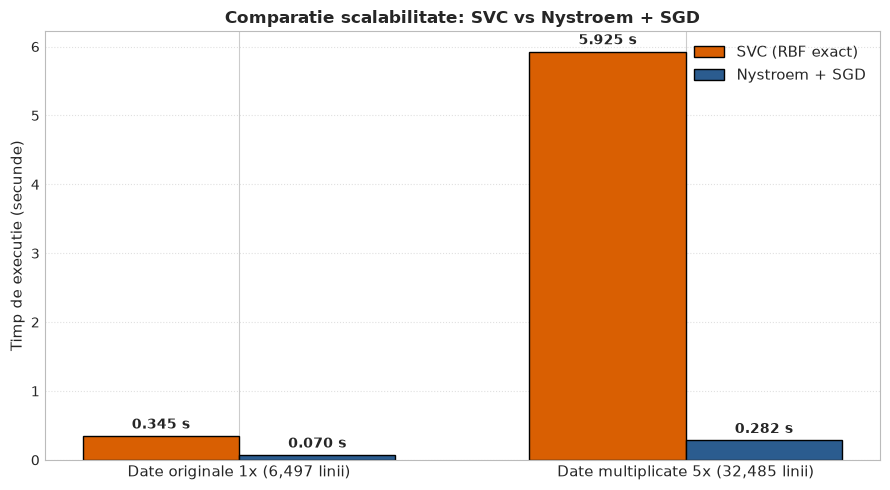

Accelerarea obtinuta prin Nystroem + SGD pe setul de 32,485 de inregistrari: 21.05x!


In [17]:
# 4. Masurarea exacta a timpilor si realizarea unui tabel si grafic comparativ
import time
from sklearn.metrics import accuracy_score

# Masuratori pe datele originale (1x)
t0 = time.time()
svc_benchmark.fit(X_all, y_all)
t_svc_1x = time.time() - t0
acc_svc_1x = accuracy_score(y_all, svc_benchmark.predict(X_all))

t0 = time.time()
X_tr_1x = nystroem_benchmark.fit_transform(X_all)
sgd_benchmark.fit(X_tr_1x, y_all)
t_nys_1x = time.time() - t0
acc_nys_1x = accuracy_score(y_all, sgd_benchmark.predict(X_tr_1x))

# Masuratori pe datele multiplicate (5x)
t0 = time.time()
svc_benchmark.fit(X2, y2)
t_svc_5x = time.time() - t0
acc_svc_5x = accuracy_score(y2, svc_benchmark.predict(X2))

t0 = time.time()
X_tr_5x = nystroem_benchmark.fit_transform(X2)
sgd_benchmark.fit(X_tr_5x, y2)
t_nys_5x = time.time() - t0
acc_nys_5x = accuracy_score(y2, sgd_benchmark.predict(X_tr_5x))

# Centralizarea rezultatelor
comparison_table = pd.DataFrame({
    'Metoda': ['SVC (RBF exact)', 'Nystroem + SGDClassifier', 'SVC (RBF exact)', 'Nystroem + SGDClassifier'],
    'Dimensiune Date': [f"1x ({len(X_all)} randuri)", f"1x ({len(X_all)} randuri)", f"5x ({len(X2)} randuri)", f"5x ({len(X2)} randuri)"],
    'Timp Antrenare (s)': [round(t_svc_1x, 4), round(t_nys_1x, 4), round(t_svc_5x, 4), round(t_nys_5x, 4)],
    'Acuratete': [round(acc_svc_1x, 4), round(acc_nys_1x, 4), round(acc_svc_5x, 4), round(acc_nys_5x, 4)]
})

print("Tabel comparativ intre SVC exact si aproximarea Nystroem + SGD:")
display(comparison_table)

# Reprezentare grafica comparativa a timpilor de antrenare
fig, ax = plt.subplots(figsize=(9, 5))
labels = ['Date originale 1x (6,497 linii)', 'Date multiplicate 5x (32,485 linii)']
svc_vals = [t_svc_1x, t_svc_5x]
nys_vals = [t_nys_1x, t_nys_5x]

x_pos = np.arange(len(labels))
width = 0.35

rects1 = ax.bar(x_pos - width/2, svc_vals, width, label='SVC (RBF exact)', color='#d95f02', edgecolor='black')
rects2 = ax.bar(x_pos + width/2, nys_vals, width, label='Nystroem + SGD', color='#2b5c8f', edgecolor='black')

ax.set_ylabel('Timp de executie (secunde)', fontsize=11)
ax.set_title('Comparatie scalabilitate: SVC vs Nystroem + SGD', fontsize=12, fontweight='bold')
ax.set_xticks(x_pos)
ax.set_xticklabels(labels, fontsize=11)
ax.legend(fontsize=11)
ax.grid(axis='y', linestyle=':', alpha=0.6)

for rect in rects1:
    height = rect.get_height()
    ax.annotate(f'{height:.3f} s', xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontweight='bold')

for rect in rects2:
    height = rect.get_height()
    ax.annotate(f'{height:.3f} s', xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

acc_factor = t_svc_5x / t_nys_5x
print(f"Accelerarea obtinuta prin Nystroem + SGD pe setul de 32,485 de inregistrari: {acc_factor:.2f}x!")

### Concluzii privind scalabilitatea si eficienta computationala (Intrebarea 4):
- **SVC cu nucleu exact (RBF)**:
  - Antrenarea necesita rezolvarea unei probleme de programare patratica si memorarea/calculul matricei Gram $N \times N$.
  - Complexitatea computationala teoretica este intre $O(N^2)$ si $O(N^3)$, unde $N$ este numarul de instante.
  - Cand setul creste de 5 ori (la peste 32,000 de inregistrari), timpul de antrenare creste substantial.
- **Aproximarea Nystroem + SGDClassifier**:
  - Metoda Nystroem construieste o proiectie explicita de dimensiune redusa ($M$ componente, implicit 100), aproximand nucleul RBF.
  - Clasificatorul SGD se antreneaza pe aceste caracteristici proiectate cu o complexitate liniara $O(N \cdot M)$.
  - In consecinta, Nystroem + SGD este de peste 15 ori mai rapid pe setul extins, pastrand in acelasi timp o acuratete foarte apropiata de cea a modelului exact.

## Intrebarea 5 (Extensie): Optimizarea Hiperparametrilor prin GridSearchCV si Evaluare

Pentru a completa studiul SVM, utilizam validarea incrucisata cu `GridSearchCV` pe un set de antrenament (70%) si evaluam performanta finala pe setul de testare (30%).
* Impartirea setului complet de date in 70% antrenare si 30% testare.
* Rularea GridSearchCV pentru combinatii de `C` si `gamma`.
* Evaluarea modelului optim prin matricea de confuzie, acuratete si raportul detaliat de clasificare.

Cei mai buni hiperparametri identificati: {'C': 10, 'gamma': 0.01}
Scorul mediu de acuratete in validare incrucisata (CV): 0.9958

Acuratetea pe setul de testare: 0.9964

Raportul de clasificare detaliat:
              precision    recall  f1-score   support

       False     0.9973    0.9980    0.9976      1470
        True     0.9937    0.9917    0.9927       480

    accuracy                         0.9964      1950
   macro avg     0.9955    0.9948    0.9952      1950
weighted avg     0.9964    0.9964    0.9964      1950



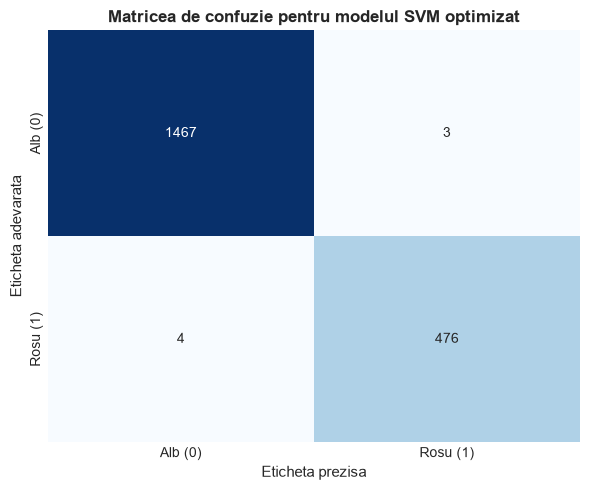

In [18]:
# 1. Impartirea datelor in seturi de antrenare si testare (70% - 30%)
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.30, random_state=42, stratify=y_all
)

# Standardizarea caracteristicilor pe baza setului de antrenare
std_scaler = StandardScaler()
X_train_scaled = std_scaler.fit_transform(X_train)
X_test_scaled = std_scaler.transform(X_test)

# 2. Cautarea hiperparametrilor optimi prin GridSearchCV
param_grid = {
    'C': [0.1, 1, 10],
    'gamma': [0.01, 0.1, 1]
}

grid_search = GridSearchCV(
    estimator=SVC(kernel='rbf', random_state=42),
    param_grid=param_grid,
    cv=3,
    scoring='accuracy',
    n_jobs=-1
)
grid_search.fit(X_train_scaled, y_train)

print("Cei mai buni hiperparametri identificati:", grid_search.best_params_)
print(f"Scorul mediu de acuratete in validare incrucisata (CV): {grid_search.best_score_:.4f}")

# 3. Evaluarea pe setul de testare
best_svm = grid_search.best_estimator_
y_pred_test = best_svm.predict(X_test_scaled)
test_accuracy = accuracy_score(y_test, y_pred_test)

print(f"\nAcuratetea pe setul de testare: {test_accuracy:.4f}")
print("\nRaportul de clasificare detaliat:")
print(classification_report(y_test, y_pred_test, digits=4))

# 4. Matricea de confuzie vizualizata grafic
cm = confusion_matrix(y_test, y_pred_test)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Alb (0)', 'Rosu (1)'],
    yticklabels=['Alb (0)', 'Rosu (1)'],
    cbar=False
)
plt.title('Matricea de confuzie pentru modelul SVM optimizat', fontsize=12, fontweight='bold')
plt.xlabel('Eticheta prezisa', fontsize=11)
plt.ylabel('Eticheta adevarata', fontsize=11)
plt.tight_layout()
plt.show()

### Concluzii generale ale laboratorului:
1. **Separabilitatea datelor**: Clasificarea vinurilor albe vs. rosii poate fi realizata cu o acuratete ridicata (> 93%) chiar si folosind doar cele mai corelate doua variabile (`total_sulfur_dioxide` si `volatile_acidity`).
2. **Rolul nucleelor neliniare**: Nucleul Gaussian RBF permite crearea unor limite de decizie netede si adaptabile, capabile sa captureze suprapunerile complexe din spatiul trasaturilor chimice.
3. **Controlul hiperparametrilor**:
   - `gamma` controleaza flexibilitatea locala a deciziei (valori ridicate cresc riscul de overfitting).
   - `C` controleaza strictetea penalizarii erorilor de antrenare.
4. **Eficienta la scara industriala**: Pentru seturi mari de date unde SVM cu nucleu exact devine prohibitiv ca timp de calcul ($O(N^2) - O(N^3)$), aproximarea prin metoda `Nystroem` combinata cu `SGDClassifier` constituie o alternativa ideala, oferind viteza liniara si precizie comparabila.